# Vitaliza · grupo 11 · Artefato de tech

**Grupo 11:** João Pedro Capelli Kanamaru, Luca Tavares Gerin e Fernanda Tiemi Mori

Análise exploratória da saída de assinantes da Vitaliza, com data de corte em 30/09/2026. Este notebook
é o roteiro da entrega: resume, em ordem, a limpeza da base, a base única por usuário, os padrões
ligados à saída e a segmentação. Cada seção aponta para os notebooks onde a conta completa está feita.

| Parte | O que responde | Notebooks |
|---|---|---|
| 1. Limpeza | O que foi corrigido, removido ou marcado em cada arquivo | 01 a 25 e `decisoes.md` |
| 2. Base única | Uma linha por usuário, com perfil, entrada, saída e uso | 39 a 43 |
| 3. Padrões de saída | Onde, quando e com que sinais os assinantes saem | 26 a 38 |
| 4. Segmentação | Cinco segmentos, com perfil, tamanho e saída histórica | 44 a 51 |

Este notebook lê só os resultados gravados em `saidas/`, que estão no repositório. Os dados do data room
e as tabelas intermediárias ficam fora do Git.

Três lentes aparecem em todas as análises: **ativos** (assinatura ativa na data), **engajamento** (alto:
treinou nos últimos 7 dias; médio: treinou no mês; baixo: 30 a 44 dias sem treinar; possível churn: 45
dias ou mais) e **saída** (assinatura encerrada).

In [1]:
import warnings
warnings.filterwarnings("ignore")
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import Image, display

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.1f}")
S = Path("../saidas")
PRETO, VERM, CINZA = "#222222", "#e5484d", "#b8b8b8"
ler = lambda nome, **k: pd.read_csv(S / f"{nome}.csv", encoding="utf-8-sig", **k)
def limpa(ax):
    for s_ in ["top", "right"]: ax.spines[s_].set_visible(False)
pct = lambda v: f"{v:.1f}%".replace(".", ",")

## 1. Limpeza da base

Os 13 arquivos do data room passaram por um diagnóstico de qualidade (completude, validade, unicidade,
datas) e por uma limpeza registrada passo a passo. Os arquivos brutos não são alterados: cada limpeza
grava uma tabela nova. Toda decisão está em `decisoes.md`, com motivo, critério e linhas afetadas.

In [2]:
linhas = []
for arq in sorted(S.glob("limpeza_*_registro.csv")):
    r = pd.read_csv(arq, encoding="utf-8-sig")
    if "tabela" in r.columns: r = r[r.tabela == r.tabela.iloc[0]]
    alt = int(r.alteradas.sum()) if "alteradas" in r.columns else np.nan
    linhas.append({"arquivo": arq.stem.replace("limpeza_", "").replace("_registro", ""), "linhas no bruto": int(r.linhas.iloc[0]),
                   "linhas depois da limpeza": int(r.linhas.iloc[-1]), "removidas": int(r.linhas.iloc[0] - r.linhas.iloc[-1]),
                   "valores alterados (soma dos passos)": alt, "passos": len(r) - 1})
lim = pd.DataFrame(linhas).set_index("arquivo")
print(lim.to_string(float_format=lambda v: f"{v:,.0f}"))
dec = [l for l in open("../decisoes.md", encoding="utf-8") if re.match(r"\| 2026-", l)]
print()
print("decisões registradas em decisoes.md:", len(dec))

                    linhas no bruto  linhas depois da limpeza  removidas  valores alterados (soma dos passos)  passos
arquivo                                                                                                              
amizades                     113480                    113207        273                                  NaN       2
assinaturas                   32643                     32583         60                                  NaN       4
atividades                  1254475                   1252488       1987                              699,459       7
campanha_ago26                14120                     14120          0                               28,347       5
eventos_assinatura           275565                    275565          0                                  NaN       4
feed_posts                   119309                    119187        122                              239,709       4
heatmaps                      25473                     

Os tratamentos que mais pesam nas análises seguintes:

- **Contas de teste** (e-mail da própria Vitaliza) saem de todas as tabelas.
- **Horários**: as lojas gravam em UTC e o site em horário de Brasília; tudo foi levado para Brasília
  antes de contar eventos por dia ou por mês.
- **Cópias**: cobranças repetidas e treinos gravados duas vezes (app e relógio) ficam com um registro só.
- **Falha de GPS** (04/05 a 28/06/2026): treinos ao ar livre sem distância são mantidos e marcados, sem
  imputação.
- **Situação do assinante numa data** vem do log de eventos, não do retrato de `assinaturas.csv`.

## 2. Base única por usuário

A tabela master (notebook 39) tem uma linha por conta e junta perfil, entrada, saída, uso do app, rede,
suporte e campanha. O uso é medido na data de referência de cada conta: o corte para quem está ativo e a
véspera da saída para quem saiu. Os notebooks 40 a 43 tratam extremos, padronizam e definem quem entra
na segmentação.

linhas (uma por conta): 63.929 | colunas: 119

grupo
identificação                3
perfil                       7
entrada                     13
saída                        9
uso                         22
comportamento               18
pagamento                    4
suporte                      3
campanha                     1
tratada para k-means        15
padronizada para k-means    23
segmentação                  1


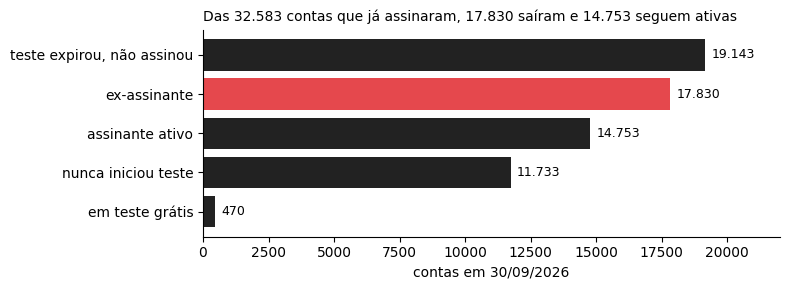

In [3]:
dic = ler("tabela_master_dicionario")
print("linhas (uma por conta):", f"{int(dic.loc[dic.coluna == 'user_id', 'preenchidas'].iloc[0]):,}".replace(",", "."), "| colunas:", len(dic))
print()
print(dic.groupby("grupo", sort=False).size().rename("colunas").to_string())
sit = ler("eda_visao_geral_situacao")
sit["situacao"] = sit.situacao.str[3:]
fig, ax = plt.subplots(figsize=(8, 3))
s = sit.set_index("situacao").contas.sort_values()
ax.barh(s.index, s.values, color=[VERM if i == "ex-assinante" else PRETO for i in s.index])
for y, v in enumerate(s.values): ax.text(v + 250, y, f"{v:,}".replace(",", "."), va="center", fontsize=9)
ax.set_xlim(0, s.max() * 1.15); ax.set_xlabel("contas em 30/09/2026"); limpa(ax)
ax.set_title("Das 32.583 contas que já assinaram, 17.830 saíram e 14.753 seguem ativas", fontsize=10, loc="left")
fig.tight_layout(); fig.savefig(S / "artefato_tech_situacao.png", dpi=130); plt.show()

## 3. Padrões ligados à saída

### 3.1 O plano mensal sai cerca de três vezes mais que o anual

Taxa mensal de saída em 2026 (perdas ÷ assinaturas ativas no início do mês), por plano e canal de
cobrança (notebook 30). A saída involuntária (falha de pagamento e chargeback) é pequena, e se concentra
no cartão pelo site.

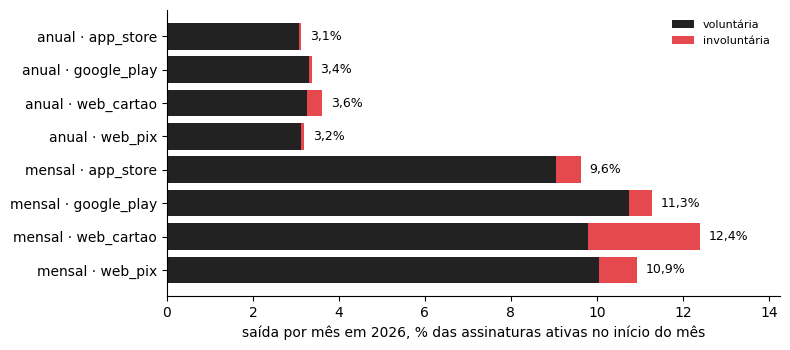

 plano canal_cobranca  churn %  voluntário %  involuntário %
 anual      app_store      3.1           3.1             0.1
 anual    google_play      3.4           3.3             0.1
 anual     web_cartao      3.6           3.3             0.3
 anual        web_pix      3.2           3.1             0.1
mensal      app_store      9.6           9.0             0.6
mensal    google_play     11.3          10.7             0.5
mensal     web_cartao     12.4           9.8             2.6
mensal        web_pix     10.9          10.0             0.9


In [4]:
cc = ler("canal_cobranca_churn_2026")
cc["rot"] = cc.plano + " · " + cc.canal_cobranca
cc = cc.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(cc.rot, cc["voluntário %"], color=PRETO, label="voluntária")
ax.barh(cc.rot, cc["involuntário %"], left=cc["voluntário %"], color=VERM, label="involuntária")
for y, v in enumerate(cc["churn %"]): ax.text(v + 0.2, y, pct(v), va="center", fontsize=9)
ax.set_xlim(0, cc["churn %"].max() * 1.15); ax.set_xlabel("saída por mês em 2026, % das assinaturas ativas no início do mês")
ax.legend(frameon=False, fontsize=8, loc="upper right"); limpa(ax)
fig.tight_layout(); fig.savefig(S / "artefato_tech_plano_canal.png", dpi=130); plt.show()
print(cc.iloc[::-1][["plano", "canal_cobranca", "churn %", "voluntário %", "involuntário %"]].to_string(index=False))

### 3.2 Quem sai por vontade própria para de treinar antes

Nível de engajamento na véspera da saída, por tipo de saída, contra os assinantes ativos no corte
(notebook 28; saídas de 17/03 a 30/09/2026, que têm histórico de treino completo). Quem desliga a
renovação já treinava menos. Quem sai por falha de pagamento estava treinando como um assinante ativo.

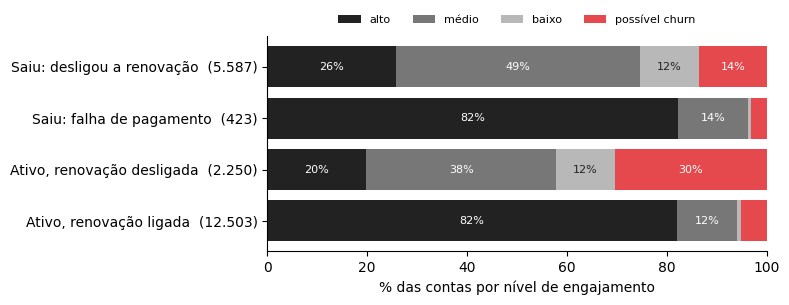

                            total  % 1. alto  % 2. médio  % 3. baixo  % 4. possível churn
grupo                                                                                    
Saiu: desligou a renovação   5587       25.8        48.7        11.8                 13.6
Saiu: falha de pagamento      423       82.3        13.9         0.7                  3.1
Ativo, renovação desligada   2250       19.8        38.1        11.7                 30.4
Ativo, renovação ligada     12503       81.9        12.1         0.8                  5.2


In [5]:
ts = ler("tipo_saida_engajamento_antes_da_saida").rename(columns={"Unnamed: 0": "grupo"}).set_index("grupo")
sel = {"saída: renovacao_desligada": "Saiu: desligou a renovação", "saída: falha_pagamento": "Saiu: falha de pagamento",
       "ativo, renovação desligada": "Ativo, renovação desligada", "ativo, renovação ligada": "Ativo, renovação ligada"}
t = ts.loc[list(sel)].rename(index=sel)
niv = ["% 1. alto", "% 2. médio", "% 3. baixo", "% 4. possível churn"]
cores = [PRETO, "#777777", CINZA, VERM]
fig, ax = plt.subplots(figsize=(8, 3.2)); esq = np.zeros(len(t))
rot = [i + "  (" + f"{int(n):,}".replace(",", ".") + ")" for i, n in zip(t.index, t.total)]
for c, cor in zip(niv, cores):
    ax.barh(rot, t[c].values, left=esq, color=cor, label=c[5:])
    for y, (v, e0) in enumerate(zip(t[c].values, esq)):
        if v >= 7: ax.text(e0 + v / 2, y, f"{v:.0f}%", ha="center", va="center", color="white" if cor != CINZA else PRETO, fontsize=8)
    esq += t[c].values
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel("% das contas por nível de engajamento"); limpa(ax)
ax.legend(frameon=False, fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.15))
fig.tight_layout(); fig.savefig(S / "artefato_tech_engajamento_saida.png", dpi=130); plt.show()
print(t[["total"] + niv].to_string())

### 3.3 No plano anual, o engajamento cai mês a mês até a renovação

Fotos mensais de fev a set/2026, lidas por mês de casa (notebook 29). No primeiro ano, a fatia com
engajamento alto cai de 87% para 47%. No mês 13 ela volta a 73%, porque só fica quem renovou.

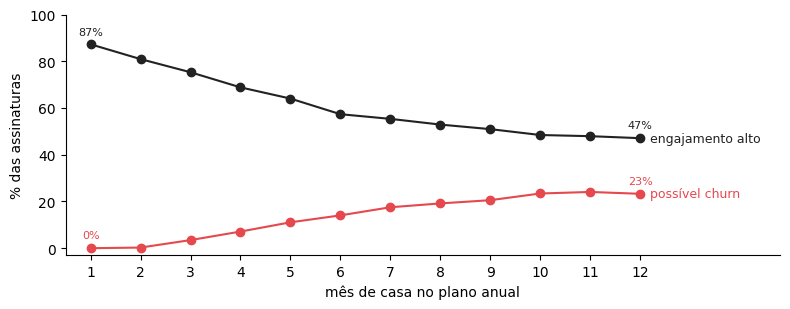

 mes_de_casa  assinatura-foto  1. alto  2. médio  3. baixo  4. possível churn
           1             3200     87.2      12.6       0.1                0.0
           2             3206     80.9      17.2       1.7                0.3
           3             3221     75.3      18.0       3.3                3.5
           4             3172     68.8      19.8       4.3                7.1
           5             3394     64.0      19.9       5.0               11.1
           6             3352     57.3      22.5       6.1               14.1
           7             3453     55.3      20.9       6.2               17.5
           8             3261     52.9      22.2       5.7               19.2
           9             3095     51.0      21.8       6.7               20.5
          10             2973     48.4      22.2       6.0               23.4
          11             2929     47.9      21.6       6.4               24.1
          12             3054     47.1      22.3       7.3      

In [6]:
an = ler("anual_engajamento_por_mes_de_casa")
a12 = an[an.mes_de_casa <= 12]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(a12.mes_de_casa, a12["1. alto"], "o-", color=PRETO); ax.plot(a12.mes_de_casa, a12["4. possível churn"], "o-", color=VERM)
ax.text(12.2, a12["1. alto"].iloc[-1], "engajamento alto", color=PRETO, fontsize=9, va="center")
ax.text(12.2, a12["4. possível churn"].iloc[-1], "possível churn", color=VERM, fontsize=9, va="center")
for col, cor in [("1. alto", PRETO), ("4. possível churn", VERM)]:
    for i in [0, len(a12) - 1]:
        ax.annotate(f"{a12[col].iloc[i]:.0f}%", (a12.mes_de_casa.iloc[i], a12[col].iloc[i]), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8, color=cor)
ax.set_xticks(range(1, 13)); ax.set_xlim(0.5, 14.8); ax.set_ylim(-3, 100)
ax.set_xlabel("mês de casa no plano anual"); ax.set_ylabel("% das assinaturas"); limpa(ax)
fig.tight_layout(); fig.savefig(S / "artefato_tech_anual.png", dpi=130); plt.show()
print(an.loc[an.mes_de_casa <= 13, ["mes_de_casa", "assinatura-foto", "1. alto", "2. médio", "3. baixo", "4. possível churn"]].to_string(index=False))

### 3.4 A falha de GPS do app no Android aparece na saída de junho e julho

Entre 04/05 e 28/06/2026 o app gravou treinos ao ar livre sem distância, só no Android. Quem teve a
falha saiu mais em junho e julho do que quem treinou ao ar livre sem falha, no Android e no iOS
(notebook 31). É uma comparação entre grupos observados, não um experimento.

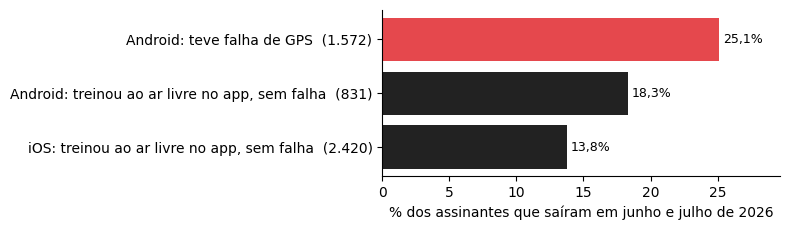

sistema                                        grupo  assinantes  % saiu jun-jul
android                         a. teve falha de GPS        1572            25.1
android     b. treinou ao ar livre no app, sem falha         831            18.3
android c. treinava ao ar livre antes, não na janela         482            19.5
android           d. não treina ao ar livre pelo app         275            16.0
    ios     b. treinou ao ar livre no app, sem falha        2420            13.8
    ios c. treinava ao ar livre antes, não na janela         421            14.0
    ios           d. não treina ao ar livre pelo app         148            15.5


In [7]:
gp = ler("google_play_falha_gps_coorte")
g = gp[gp.grupo.str[0].isin(["a", "b"])].copy()
g["rot"] = g.sistema.map({"android": "Android", "ios": "iOS"}) + ": " + g.grupo.str[3:]
g = g.sort_values("% saiu jun-jul")
fig, ax = plt.subplots(figsize=(8, 2.4))
ax.barh([r + "  (" + f"{n:,}".replace(",", ".") + ")" for r, n in zip(g.rot, g.assinantes)], g["% saiu jun-jul"], color=[VERM if x.startswith("a") else PRETO for x in g.grupo])
for y, v in enumerate(g["% saiu jun-jul"]): ax.text(v + 0.3, y, pct(v), va="center", fontsize=9)
ax.set_xlim(0, g["% saiu jun-jul"].max() * 1.18); ax.set_xlabel("% dos assinantes que saíram em junho e julho de 2026"); limpa(ax)
fig.tight_layout(); fig.savefig(S / "artefato_tech_gps.png", dpi=130); plt.show()
print(gp[["sistema", "grupo", "assinantes", "% saiu jun-jul"]].to_string(index=False))

### 3.5 Campanha de agosto de 2026: cupom e desafio seguram o mensal, nada segura o anual na renovação

Sorteio em quatro grupos em 10/08/2026; saída do envio até o corte, lida por intenção de tratar
(notebook 33). No mensal, cupom e desafio reduzem a saída contra o controle. No anual com aniversário na
janela, nenhuma mensagem reduz a saída.

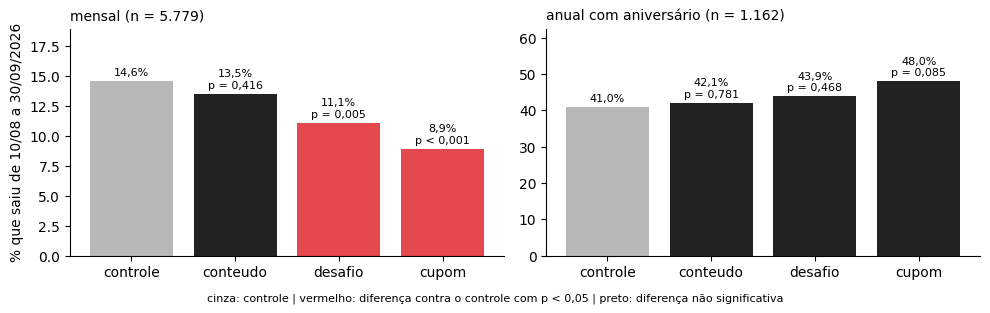

              recorte    grupo    n  casos    %  dif. (p.p.)  IC95 inf  IC95 sup  valor-p
                todos controle 3579    352  9.8          NaN       NaN       NaN      NaN
                todos conteudo 3554    325  9.1       -0.691      -2.1     0.670    0.320
                todos  desafio 3515    306  8.7         -1.1      -2.5     0.220    0.101
                todos    cupom 3472    275  7.9         -1.9      -3.2    -0.588    0.005
               mensal controle 1440    210 14.6          NaN       NaN       NaN      NaN
               mensal conteudo 1463    198 13.5         -1.0      -3.6       1.5    0.416
               mensal  desafio 1456    162 11.1         -3.5      -5.9      -1.0    0.005
               mensal    cupom 1420    127  8.9         -5.6      -8.0      -3.3    0.000
anual com aniversário controle  305    125 41.0          NaN       NaN       NaN      NaN
anual com aniversário conteudo  273    115 42.1          1.1      -6.9       9.2    0.781
anual com 

In [8]:
cp = ler("campanha_ago26_churn_por_grupo")
fig, axs = plt.subplots(1, 2, figsize=(10, 3), sharey=False)
for ax, rec in zip(axs, ["mensal", "anual com aniversário"]):
    d = cp[cp.recorte == rec]
    base = d.loc[d.grupo == "controle", "%"].iloc[0]
    sig = (d["valor-p"] < 0.05).fillna(False).to_numpy()
    ax.bar(d.grupo, d["%"], color=[CINZA if g_ == "controle" else (VERM if s_ else PRETO) for g_, s_ in zip(d.grupo, sig)])
    for x, (v, p) in enumerate(zip(d["%"], d["valor-p"])):
        ax.text(x, v + d["%"].max() * 0.02, pct(v) + ("" if pd.isna(p) else ("\np < 0,001" if p < 0.001 else f"\np = {p:.3f}".replace(".", ","))), ha="center", va="bottom", fontsize=8)
    ax.set_ylim(0, d["%"].max() * 1.3); ax.set_title(f"{rec} (n = {int(d.n.sum()):,})".replace(",", "."), fontsize=10, loc="left"); limpa(ax)
axs[0].set_ylabel("% que saiu de 10/08 a 30/09/2026")
fig.text(0.5, -0.02, "cinza: controle | vermelho: diferença contra o controle com p < 0,05 | preto: diferença não significativa", ha="center", fontsize=8)
fig.tight_layout(); fig.savefig(S / "artefato_tech_campanha.png", dpi=130, bbox_inches="tight"); plt.show()
print(cp.to_string(index=False, float_format=lambda v: f"{v:.3f}" if abs(v) < 1 else f"{v:.1f}"))

### 3.6 Outros recortes

Canal de aquisição (notebook 27) e tipo de treino principal (notebooks 34 a 36). Quem chega por
influenciador e quem tem a corrida como treino principal saem mais no plano mensal. Na pesquisa de saída
(641 respostas, só de quem cancelou pelo site), "objetivo cumprido" é o motivo mais citado entre
corredores.

In [9]:
ca = ler("canal_aquisicao_ativos_engajamento_churn")
print(ca[["canal_aquisicao", "ativos", "% 1. alto", "churn mensal 2026 %"]].sort_values("churn mensal 2026 %", ascending=False).to_string(index=False))
print()
tt = ler("tipo_treino_ativos_engajamento_churn")
print(tt[["principal", "ativos", "% anual", "% 1. alto", "churn % mensal", "churn % anual"]].sort_values("churn % mensal", ascending=False).to_string(index=False))
print()
ps = ler("pesquisa_saida_motivo_por_tipo_treino").set_index("principal")
print((ps.drop(columns="total").div(ps.total, axis=0) * 100).loc[["corrida", "funcional", "total"]].to_string())

     canal_aquisicao  ativos  % 1. alto  churn mensal 2026 %
       influenciador    2495       74.3                  9.0
            meta_ads    2425       70.1                  6.6
          google_ads    1532       71.3                  6.4
            organico    4634       72.6                  6.2
parceria_corporativa    1439       73.2                  5.9
           indicacao    2228       72.9                  5.9

 principal  ativos  % anual  % 1. alto  churn % mensal  churn % anual
sem treino     754     99.6        0.0            17.9            8.0
   corrida    5358     59.6       73.5            13.8            2.7
     pedal    1373     56.2       77.4            12.0            2.9
 caminhada    1777     50.4       74.5             9.8            3.5
      yoga     258     60.1       65.5             9.5            6.4
     forca    1759     53.4       77.1             9.3            2.6
 funcional    3474     51.0       81.6             8.6            1.8

           

## 4. Segmentação

**Como foi feita** (notebooks 44 a 50). K-means com quatro grupos nos 13.999 assinantes ativos em
30/09/2026 que treinaram nos 90 dias até o corte, com cinco variáveis padronizadas: treinos por semana,
dias sem treino, tempo de casa, % dos treinos ao ar livre e nível de engajamento. Os 754 ativos sem
treino na janela formam um quinto segmento, por regra. Foram testadas seis versões de variáveis e k de 2
a 8; a escolha está registrada em `decisoes.md`.

**Por que k = 4.** A inércia ainda cai bem até o quarto grupo; a silhueta é 0,30 (fraca: os grupos têm
fronteiras difusas); os rótulos são estáveis (Rand 0,98 ou mais em reamostragens); e cada grupo pede uma
ação diferente.

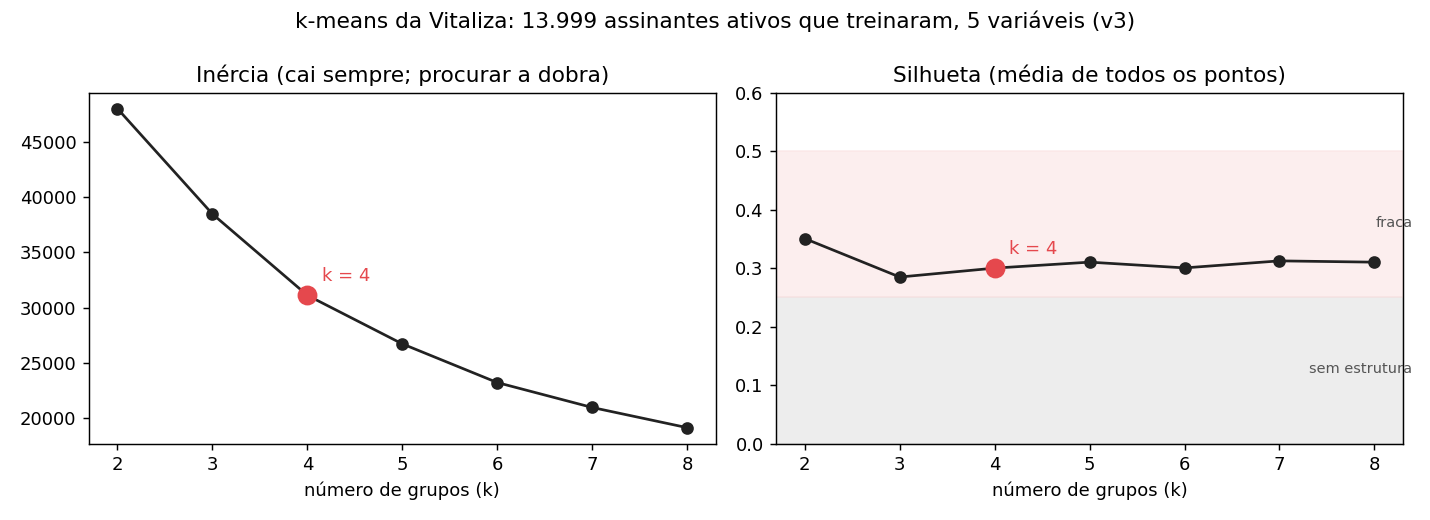

Perfil em 30/09/2026 (medianas)
segmento              Ativos ao ar livre Ativos em ambiente fechado Recém-chegados Esfriando Inativos em 90 dias (regra) Total de ativos
assinantes                          5001                       4030           2092      2876                         754           14753
% dos ativos                        33.9                       27.3           14.2      19.5                         5.1           100.0
treinos por semana                   2.6                        2.4            0.9       0.6                         0.0             1.8
dias sem treinar                     1.0                        1.0            2.0      18.0                       131.0             2.0
meses de casa                       10.8                       10.5            0.9       9.9                        15.5             8.6
% ao ar livre                       80.8                       14.5           70.0      76.3                         NaN            71.4
% plano a

In [10]:
display(Image(filename=str(S / "segmentacao_oficial_curvas.png"), width=820))
pf = ler("segmentacao_oficial_perfis").set_index("segmento")
cols = {"assinantes": "assinantes", "pct_ativos": "% dos ativos", "treinos_por_semana": "treinos por semana", "dias_sem_treinar": "dias sem treinar",
        "meses_de_casa": "meses de casa", "pct_ar_livre": "% ao ar livre", "pct_anual": "% plano anual", "pct_engaj_alto": "% engajamento alto",
        "pct_renovacao_desligada": "% renovação desligada", "tipo_principal_mais_comum": "treino mais comum"}
print("Perfil em 30/09/2026 (medianas)")
print(pf[list(cols)].rename(columns=cols).T.to_string())

### 4.1 Saída histórica de cada segmento

Em 30/09 ninguém dos segmentos saiu ainda. Para medir a saída, o notebook 51 aplica a mesma régua a quem
estava ativo em 30/06/2026 e conta quem saiu de julho a setembro.

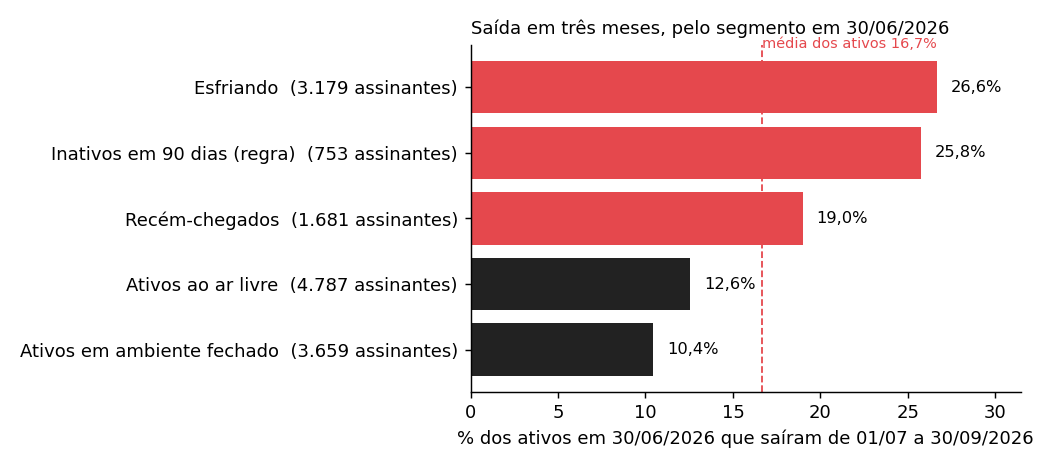

segmento_em_30jun     Ativos ao ar livre  Ativos em ambiente fechado  Recém-chegados  Esfriando  Inativos em 90 dias (regra)  Total de ativos em 30/06
assinantes em 30/06              4,787.0                     3,659.0         1,681.0    3,179.0                        753.0                  14,059.0
% dos ativos                        34.0                        26.0            12.0       22.6                          5.4                     100.0
% engajamento alto                  97.8                        94.0            91.5        0.0                          0.0                      68.7
saíram jul a set                   601.0                       382.0           319.0      847.0                        194.0                   2,343.0
% saída                             12.6                        10.4            19.0       26.6                         25.8                      16.7
% de todas as saídas                25.6                        16.3            13.6       36.

In [11]:
sh = ler("segmentacao_oficial_saida_historica").set_index("segmento_em_30jun")
display(Image(filename=str(S / "segmentacao_oficial_saida_historica.png"), width=760))
cols = {"assinantes_30jun": "assinantes em 30/06", "pct_dos_ativos": "% dos ativos", "pct_engaj_alto": "% engajamento alto", "sairam_jul_set": "saíram jul a set",
        "pct_saida": "% saída", "pct_das_saidas": "% de todas as saídas", "pct_saida_mensal": "% saída no mensal", "pct_saida_anual": "% saída no anual"}
print(sh[list(cols)].rename(columns=cols).T.to_string())
print()
print("Para onde foi cada grupo até 30/09 (% da linha)")
print(ler("segmentacao_oficial_saida_historica_destino").set_index("segmento_em_30jun").to_string())

**Leitura.** Esfriando e Inativos saem cerca de 1,6 vez a média; juntos eram 28% dos ativos em 30/06 e
responderam por 44% das saídas do trimestre. No plano anual a diferença é maior: de 21,6% a 25,6% nesses
dois grupos, contra 3,6% a 4,7% nos dois grupos ativos. Os Recém-chegados saem acima da média só pelo
plano mensal.

## 5. Limitações

- **Histórico de treinos curto**: os treinos começam em 01/01/2026, então engajamento e tipo de treino só
  existem para 2026, e a saída histórica por segmento usa uma janela só (julho a setembro).
- **Segmentos com fronteiras difusas**: silhueta de 0,30. Os grupos são úteis para priorizar, não para
  classificar cada assinante com certeza.
- **Recência conta duas vezes** na segmentação (dias sem treino e nível de engajamento), de propósito.
- **Associação, não causa**: fora a campanha de agosto, que foi sorteada, os padrões comparam grupos
  observados.
- **Pesquisa de saída**: 641 respostas, só de quem cancelou pelo site de junho a setembro de 2026.
- **Sistema e relógio** são a situação na exportação, sem data.
- **Mapas de calor** foram indexados e limpos, mas não entram nas análises desta entrega.